# **Gaussian Naive Bayes from Scratch**
---
Member1 : Naglaa Mohamed Fathy || ID:20240626 .


Member2 : Habiba Khaled Hussien || ID:20242100 .




# *Task one: Data Preparation*
---

**Objective**: Load the Breast Cancer dataset and prepare it for training and testing our Gaussian Naive Bayes classifier.

*1.1-load data*

In [243]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer

np.random.seed(42)

data = load_breast_cancer()
x = data.data
y= data.target
print("Dataset loaded successfully!")
print("Features(X):", x.shape)
print("Target(Y):", y.shape)
print("Classes Names:", data.target_names)

Dataset loaded successfully!
Features(X): (569, 30)
Target(Y): (569,)
Classes Names: ['malignant' 'benign']


 *1.2-startification*

In [244]:
def train_test_split(x,y,test_size=0.2,seed=42):
    np.random.seed(seed)
    train_indices=[]
    test_indices=[]
    classes=np.unique(y)
    for cls in classes:
        class_indices=np.where(y==cls)[0]
        np.random.shuffle(class_indices)
        test_count = round(len(class_indices) * test_size)
        test_indices.extend(class_indices[:test_count])
        train_indices.extend(class_indices[test_count:])

    np.random.shuffle(train_indices)
    np.random.shuffle(test_indices)    
    X_train = x[train_indices]
    X_test = x[test_indices]

    y_train = y[train_indices]
    y_test = y[test_indices]
    
    return X_train, X_test, y_train, y_test

*1.3-test the spliting(20,80)*

In [245]:
X_train, X_test, y_train, y_test = train_test_split(x, y)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)


print("\nTraining class counts:")
print("Malignant:", np.sum(y_train == 0))
print("Benign:", np.sum(y_train == 1))

print("\nTesting class counts:")
print("Malignant:", np.sum(y_test == 0))
print("Benign:", np.sum(y_test == 1))

Training set: (456, 30)
Testing set: (113, 30)

Training class counts:
Malignant: 170
Benign: 286

Testing class counts:
Malignant: 42
Benign: 71


---
*1.4-Answering Question:*

**Does GNB need feature scaling?**


Gaussian Naive Bayes generally does not require feature scaling because it calculates a separate mean and variance for each feature. However, we should test both versions and compare their accuracy with and without standardization to verify whether scaling makes a difference in our dataset.

In [246]:

mean = np.mean(X_train, axis=0)
std = np.std(X_train, axis=0)

std[std == 0] = 1

X_train_scaled = (X_train - mean) / std
X_test_scaled = (X_test - mean) / std

print("Average feature mean:", np.mean(np.mean(X_train_scaled, axis=0)))
print("Average feature std:", np.mean(np.std(X_train_scaled, axis=0)))

Average feature mean: 3.3112421998608752e-16
Average feature std: 1.0


*a simple class to test*

In [247]:
def simple_gnb_predict(X_train, y_train, X_test):
    classes = np.unique(y_train)

    priors = []
    means = []
    variances = []

    for cls in classes:
        X_class = X_train[y_train == cls]

        priors.append(len(X_class) / len(X_train))
        means.append(np.mean(X_class, axis=0))
        variances.append(np.var(X_class, axis=0))

    priors = np.array(priors)
    means = np.array(means)
    variances = np.array(variances)

    epsilon = 1e-9 * np.var(X_train, axis=0).max()
    variances += epsilon

    scores = []

    for cls_index in range(len(classes)):
        log_gaussian = (
            -0.5 * np.log(2 * np.pi * variances[cls_index])
            - ((X_test - means[cls_index]) ** 2)
            / (2 * variances[cls_index])
        )

        score = np.log(priors[cls_index]) + np.sum(log_gaussian, axis=1)
        scores.append(score)

    scores = np.array(scores).T

    predictions = classes[np.argmax(scores, axis=1)]

    return predictions

*1)Feature Scaling Comparison*


In [248]:
y_pred_original = simple_gnb_predict(
    X_train, y_train, X_test
)

y_pred_scaled = simple_gnb_predict(
    X_train_scaled, y_train, X_test_scaled
)

accuracy_original = np.mean(y_pred_original == y_test)
accuracy_scaled = np.mean(y_pred_scaled == y_test)

print("Accuracy without scaling:", accuracy_original)
print("Accuracy with scaling:", accuracy_scaled)

Accuracy without scaling: 0.9380530973451328
Accuracy with scaling: 0.9380530973451328


**Feature Scaling Experiment:**

We applied standardization using the mean and standard deviation calculated from the training data, then used the same statistics to transform the test data. We trained Gaussian Naive Bayes on both the original and standardized datasets.

Both models achieved an accuracy of **93.81%**. This indicates that feature scaling did not affect the classification performance in our experiment. Gaussian Naive Bayes models each feature using its own mean and variance, making it generally insensitive to feature scaling.

---
# *Task Two: Implement GaussianNaiveBayes*
---

*2.1-Prior probability:*

how likely a class is before examining any features.

**formula :**

P(c)=Number of samples in class / Total number of samples


In [249]:
classes=np.unique(y_train)
class_prior={}
for cls in classes:
    class_count=np.sum(y_train==cls)
    class_prior[cls]= class_count/len(y_train)
print("Class_priors: ")   
print(class_prior) 

Class_priors: 
{np.int64(0): np.float64(0.37280701754385964), np.int64(1): np.float64(0.6271929824561403)}


---
**2.2-Means and Variances:**

*Mean (theta)*: the average value of a feature among samples belonging to a particular class

*Variance (var)* : Variance measures how spread out the values are around their mean.

In [250]:
theta=[]
var=[]
for c in classes:
    x_class=X_train[y_train==c]
    class_mean=np.mean(x_class,axis=0)
    class_var=np.var(x_class,axis=0)
    theta.append(class_mean)
    var.append(class_var)
theta=np.array(theta)
var=np.array(var)
print("Means shape:", theta.shape)
print("Variances shape:",var.shape)
    


Means shape: (2, 30)
Variances shape: (2, 30)


*inspect the first five feature means for each class*

In [251]:
print("Malignant means (first 5 features):")
print(theta[0][:5])

print("\nBenign means (first 5 features):")
print(theta[1][:5])

Malignant means (first 5 features):
[1.73296471e+01 2.13794706e+01 1.14485765e+02 9.65445882e+02
 1.03343294e-01]

Benign means (first 5 features):
[1.20680594e+01 1.80081119e+01 7.75604895e+01 4.57037762e+02
 9.28576224e-02]


---
**2.3- Variance Smoothing**

prevents numerical issues when a feature has a very small variance.

In [252]:
var_smoothing =1e-9
max_var=var_smoothing*np.var(X_train,axis=0).max()
var=var+max_var
print("largest variance across all features", max_var)
print("Minimum variance after smoothing:", np.min(var))

largest variance across all features 0.0003165948974868709
Minimum variance after smoothing: 0.00032093835987219964


---
**2.4-Implementing the GaussianNaiveBayes Class— Parameter Estimation**

In [253]:
class GNBayes:
    def __init__(self,var_smoothing=1e-9):
        self.var_smoothing=var_smoothing
    
    def fit(self,x,y):
        self.classes=np.unique(y)
        self.class_prior=[]
        self.theta=[]
        self.var=[]

        for cl in self.classes:
            x_class=x[y==cl]
            self.class_prior.append(len(x_class)/len(x))
            self.theta.append(np.mean(x_class, axis=0))
            self.var.append(np.var(x_class,axis=0))

        self.class_prior=np.array(self.class_prior)
        self.theta=np.array(self.theta)
        self.var=np.array(self.var)

        max_var = self.var_smoothing * np.var(x, axis=0).max()
        self.var+=max_var
        self.max_var=max_var

        return self
    
    def _log_gaussian(self, X):                     
        return -0.5 * np.log(2 * np.pi * self.var)  - ((X[:, None, :] - self.theta) ** 2) / (2 * self.var)         
    
    def _log_posterior(self, X):                    
        log_likelihood = self._log_gaussian(X).sum(axis=2)   
        return np.log(self.class_prior) + log_likelihood
    
    
    def predict(self, X):
        return self.classes[np.argmax(self._log_posterior(X), axis=1)]
    
    def predict_proba(self, X):                     
        log = self._log_posterior(X)                 
        log = log - log.max(axis=1, keepdims=True)
        proba = np.exp(log)
        return proba / proba.sum(axis=1, keepdims=True)
    
    


**why you use logarithms?**

We calculate the logarithm of the probabilities instead of multiplying many small probabilities. This prevents numerical underflow. Since logarithm is a monotonic function, the class with the highest probability also has the highest log-probability.

---

**2.5-Sanity test**

In [254]:
X_sanity = np.array([
    [1.0],
    [2.0],
    [3.0],
    [5.0],
    [6.0],
    [7.0]
])

y_sanity = np.array([0, 0, 0, 1, 1, 1])

use x=3.5 as the test point for our posterior calculation.


p(y0)=0.5 ,p(y1)=0.5

*means :*

M0=(1+2+3)/3=2

m1=(5+6+7)/3=6

*Variances :*

v0=2/3

v1=2/3

*posterior :*

p(x|y0)=0.0904

P(x|y1)=0.0045

*Bayes' rule :*
P(y0|x)=0.9525


P(y1|x)=0.0474


**the expected prediction is Class y0**


In [255]:
sanity_model = GNBayes()
sanity_model.fit(X_sanity, y_sanity)

print("Class priors:", sanity_model.class_prior)
print("Means:", sanity_model.theta)
print("Variances:", sanity_model.var)
x_value = np.array([[3.5]])
probabilities = sanity_model.predict_proba(x_value)
prediction = sanity_model.predict(x_value)


print("Predicted probabilities:", probabilities)
print("log posterior:", sanity_model._log_posterior(x_value))
print("Predicted class:", prediction)

expected_probabilities = np.array([[0.952574, 0.047426]])
print("Probabilities match:",
      np.allclose(probabilities, expected_probabilities, atol=1e-5))

print("Prediction is correct:",
      prediction[0] == 0)

Class priors: [0.5 0.5]
Means: [[2.]
 [6.]]
Variances: [[0.66666667]
 [0.66666667]]
Predicted probabilities: [[0.95257413 0.04742587]]
log posterior: [[-3.09685315 -6.09685313]]
Predicted class: [0]
Probabilities match: True
Prediction is correct: True


We ran the same data through our GNB implementation and compared its results with our hand calculations to verify that the model is working correctly.

---

# *Task three : Evaluation Metrics from Scratch*
---

 **3.1-Accuracy**

In [256]:
def accuracy(y_true, y_pred):
    correct = np.sum(y_true == y_pred)
    total = len(y_true)
    return correct / total

y_true = np.array([0, 0, 1, 1, 1])
y_pred = np.array([0, 1, 1, 1, 0])
print("Accuracy:", accuracy(y_true, y_pred))

Accuracy: 0.6


---
**3.2-Confusion Matrix**

In [257]:
def confusion_matrix(y_true, y_pred):
    classes=np.unique(np.concatenate((y_true, y_pred)))
    matrix = np.zeros((len(classes), len(classes)), dtype=int)
    
    for i, actual in enumerate(classes):
        for j, predicted in enumerate(classes):
            matrix[i , j] = np.sum((y_true == actual) &(y_pred == predicted))
                  
    return matrix
print("Confusion Matrix:", confusion_matrix(y_true, y_pred))

Confusion Matrix: [[1 1]
 [1 2]]


---
**3.3-Precision, Recall and F1-Score**

In [258]:
def precision_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    precision = []
    for i in range(len(cm)):
        tp = cm[i, i]
        fp = np.sum(cm[:,i])-tp
        if tp + fp == 0:
            precision.append(0.0)
        else:
            precision.append(tp / (tp + fp))
    return np.array(precision)
print("Precision Score:", precision_score(y_true, y_pred))

Precision Score: [0.5        0.66666667]


In [259]:
def recall_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    recall = []
    for i in range(len(cm)):
        tp = cm[i,i]
        fn= np.sum(cm[i,:])-tp
        
        if tp + fn ==0:
            recall.append(0.0)
        else:
            recall.append(tp / (tp + fn))
    return np.array(recall)
print("Recall Score:", recall_score(y_true, y_pred))

Recall Score: [0.5        0.66666667]


In [260]:
def f1_score(y_true,y_pred):
    precision = precision_score(y_true,y_pred)
    recall = recall_score(y_true,y_pred)
    f1=[]
    for i in range(len(precision)):
        if precision[i] + recall[i] == 0:
            f1.append(0.0)
        else:
            f1.append(2 * (precision[i] * recall[i]) / (precision[i] + recall[i]))
    return np.array(f1)

print("F1 Score:", f1_score(y_true, y_pred))

F1 Score: [0.5        0.66666667]


---
**3.4-Macro Average**

In [261]:
def macro_average(scores):
    return np.mean(scores)

print("Macro Average Precision:", macro_average(precision_score(y_true, y_pred)))
print("Macro Average Recall:", macro_average(recall_score(y_true, y_pred)))
print("Macro Average F1 Score:", macro_average(f1_score(y_true, y_pred)))

Macro Average Precision: 0.5833333333333333
Macro Average Recall: 0.5833333333333333
Macro Average F1 Score: 0.5833333333333333


---
**3.5-Testing Gaussian Naive Bayes on Breast Cancer Dataset**

In [262]:
gnb_model = GNBayes()
gnb_model.fit(X_train, y_train)
y_pred = gnb_model.predict(X_test)

In [263]:
print("Accuracy:", accuracy(y_test, y_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-Score:", f1_score(y_test, y_pred))

print("Macro Precision:", macro_average(precision_score(y_test, y_pred)))
print("Macro Recall:", macro_average(recall_score(y_test, y_pred)))
print("Macro F1-Score:", macro_average(f1_score(y_test, y_pred)))

Accuracy: 0.9380530973451328
Confusion Matrix:
[[40  2]
 [ 5 66]]
Precision: [0.88888889 0.97058824]
Recall: [0.95238095 0.92957746]
F1-Score: [0.91954023 0.94964029]
Macro Precision: 0.9297385620915033
Macro Recall: 0.9409792085848423
Macro F1-Score: 0.9345902588274209


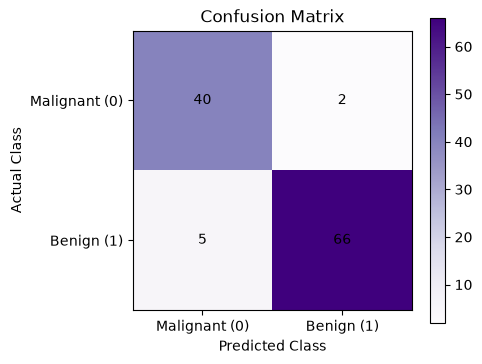

In [264]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
plt.imshow(cm, cmap="Purples")
plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks([0, 1], ["Malignant (0)", "Benign (1)"])
plt.yticks([0, 1], ["Malignant (0)", "Benign (1)"])

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i, j], ha="center", va="center")
        
plt.colorbar()
plt.tight_layout()
plt.show()

---

# *Task Four : Experiments*
---

Investigate what happens when we duplicate one strongly informative feature in our Breast Cancer dataset.

*4.1) strongly informative feature :*

In [265]:
class_0 = X_train[y_train == 0]
class_1 = X_train[y_train == 1]

mean_difference = np.abs( np.mean(class_0, axis=0) - np.mean(class_1, axis=0))
feature_std = np.std(X_train, axis=0)
separation = mean_difference / feature_std
best_feature_index = np.argmax(separation)
print("Feature index:", best_feature_index)
print("Feature name:", data.feature_names[best_feature_index])
print("Separation score:", separation[best_feature_index])

Feature index: 27
Feature name: worst concave points
Separation score: 1.6170604395362143


---
*4.2) duplicated datasets :*

"k copies" means the original feature plus k extra identical columns. k = 0 is the baseline (no duplication).

In [266]:
copies_list = [0,1, 3, 5, 10]

duplicated_datasets = {}

for n in copies_list:
    x_train_dup = np.column_stack([X_train] + [X_train[:, best_feature_index]] * n)
    x_test_dup = np.column_stack([X_test] + [X_test[:, best_feature_index]] * n )
    duplicated_datasets[n] = (x_train_dup, x_test_dup)

    print(f"{n:2d} copies:")
    print("Training shape:", x_train_dup.shape)
    print("Testing shape:", x_test_dup.shape)

 0 copies:
Training shape: (456, 30)
Testing shape: (113, 30)
 1 copies:
Training shape: (456, 31)
Testing shape: (113, 31)
 3 copies:
Training shape: (456, 33)
Testing shape: (113, 33)
 5 copies:
Training shape: (456, 35)
Testing shape: (113, 35)
10 copies:
Training shape: (456, 40)
Testing shape: (113, 40)


---
*4.3) Train Models :*

In [267]:
models = {}

for n in copies_list:
    X_train_dup, X_test_dup = duplicated_datasets[n]

    model = GNBayes()
    model.fit(X_train_dup, y_train)

    models[n] = model

    print(f"Model with {n} copies trained successfully.")

Model with 0 copies trained successfully.
Model with 1 copies trained successfully.
Model with 3 copies trained successfully.
Model with 5 copies trained successfully.
Model with 10 copies trained successfully.


Each model learns its own means and variances based on the number of duplicated features.

---
*4.4) Experiment :*

In [268]:
results = {
    "copies": [],
    "accuracy": [],
    "avg_confidence": [],
    "conf_wrong": [],
    "n_wrong": [],
    "log_odds": []
}

for n in copies_list:
    
    X_train_dup, X_test_dup = duplicated_datasets[n]
    y_pred = models[n].predict(X_test_dup)
    y_proba = models[n].predict_proba(X_test_dup)
    wrong = (y_pred != y_test)
    log_post = models[n]._log_posterior(X_test_dup)      
    log_odds = np.abs(log_post[:, 1] - log_post[:, 0])
    conf = y_proba.max(axis=1)  
    acc = np.mean(y_pred == y_test)

    avg_confidence = np.mean(np.max(y_proba, axis=1))

    results["copies"].append(n)
    results["accuracy"].append(acc)
    results["avg_confidence"].append(avg_confidence)
    results["conf_wrong"].append(conf[wrong].mean()  if wrong.any() else np.nan)    
    results["n_wrong"].append(int(wrong.sum()))
    results["log_odds"].append(log_odds.mean())
header = (f"{'extra copies':>12} {'accuracy':>9} {'avg max prob':>13} " f"{'avg prob (wrong)':>17} {'# wrong':>8} {'mean |log-odds|':>16}")
print(header)
print("-" * len(header))
for i in range(len(results["copies"])):
    print(f"{results['copies'][i]:>12d} {results['accuracy'][i]:>9.4f} "
          f"{results['avg_confidence'][i]:>13.4f} {results['conf_wrong'][i]:>17.4f} "
          f"{results['n_wrong'][i]:>8d} {results['log_odds'][i]:>16.2f}")


extra copies  accuracy  avg max prob  avg prob (wrong)  # wrong  mean |log-odds|
--------------------------------------------------------------------------------
           0    0.9381        0.9994            0.9911        7            63.45
           1    0.9381        0.9996            0.9943        7            66.45
           3    0.9381        0.9987            0.9802        7            72.44
           5    0.9469        0.9985            0.9990        6            78.47
          10    0.9469        0.9941            0.9980        6            93.63


---
**4.5) plot the accuracy :**

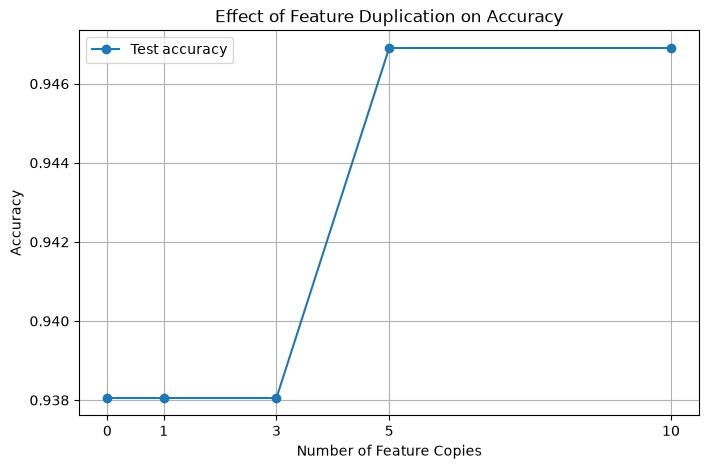

In [269]:
import matplotlib.pyplot as plot
plot.figure(figsize=(8,5))
plot.plot(results["copies"],results["accuracy"],marker="o",label="Test accuracy")
plot.xlabel("Number of Feature Copies")
plot.ylabel("Accuracy")
plot.title("Effect of Feature Duplication on Accuracy")
plot.xticks(results["copies"])
plt.legend()
plot.grid(True)
plot.show()

---
**4.6) Plot Average max predicted probability:**

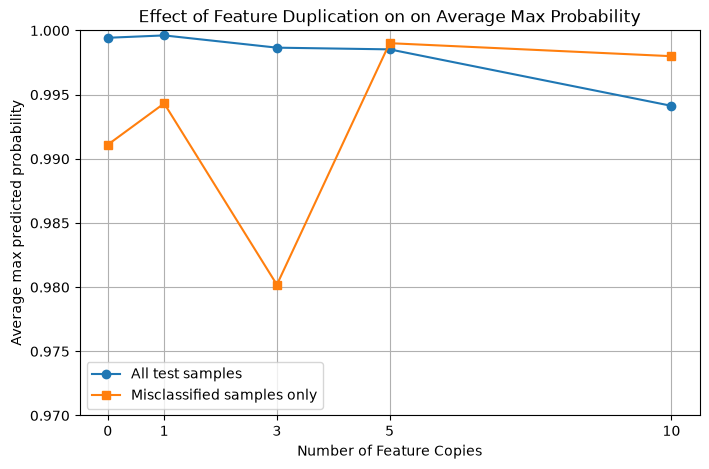

In [270]:
plot.figure(figsize=(8,5))
plot.plot(results["copies"],results["avg_confidence"],marker="o",label="All test samples")
plot.plot(results["copies"], results["conf_wrong"], marker="s", label="Misclassified samples only")

plot.xlabel("Number of Feature Copies")
plot.ylabel("Average max predicted probability")
plot.title("Effect of Feature Duplication on on Average Max Probability")
plot.xticks(results["copies"])
plt.ylim(0.97, 1.0)
plt.legend()
plot.grid(True)
plot.show()


**4.7) Plot Log-odds magnitude :**

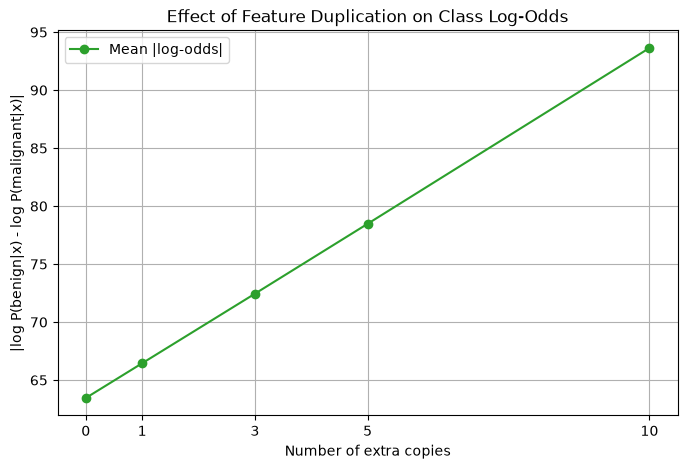

In [271]:
plot.figure(figsize=(8, 5))
plot.plot(results["copies"],results["log_odds"] ,marker="o", color="tab:green", label="Mean |log-odds|")
plot.title("Effect of Feature Duplication on Class Log-Odds")
plot.xlabel("Number of extra copies")
plot.ylabel("|log P(benign|x) - log P(malignant|x)|")
plot.xticks(results["copies"])
plot.legend()
plot.grid(True)
plot.show()

**Effect of Feature Duplication:**

We selected the most informative feature, *worst concave points*, and added n extra identical copies of it (k = 0, 1, 3, 5, 10) to investigate how repeated information affects Gaussian Naive Bayes.

Accuracy stayed essentially unchanged: it went from 93.81% to 94.69%, which is a difference of one test sample (7 mistakes became 6), so we do not consider it a real improvement. The average maximum predicted probability was already saturated near 1 at k = 0 (99.94%) and did not increase with duplication (99.41% at k = 10), so probabilities alone hide the effect. The mean absolute log-odds between the two classes, however, rose steadily by about 3 for every extra copy, from 63.45 to 93.63. This happens because Gaussian Naive Bayes adds the same log-likelihood term again for each copy, so it counts one piece of evidence k + 1 times.

A duplicated column is perfectly correlated with the original, which is the worst possible violation of the conditional independence assumption. The model becomes more extremly confident  without learning anything new. It is also visible on the misclassified samples, where the model remains 98–99.9% confident while being wrong.

---

# *Task Five : Visualization*
---

**5.1-Gaussian Distribution for Each Feature**

In [272]:
import matplotlib.pyplot as plt

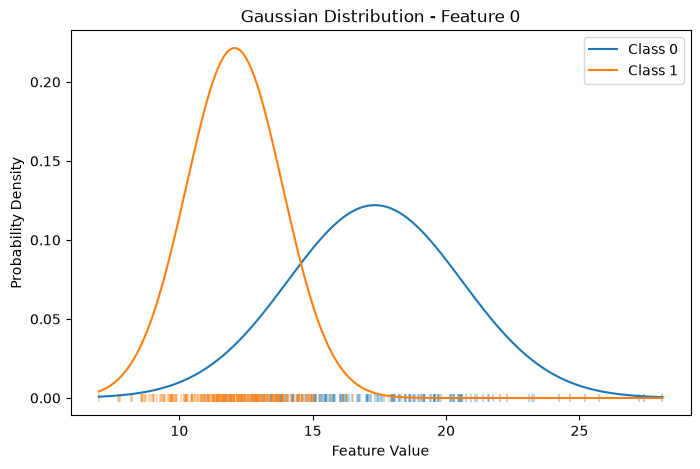

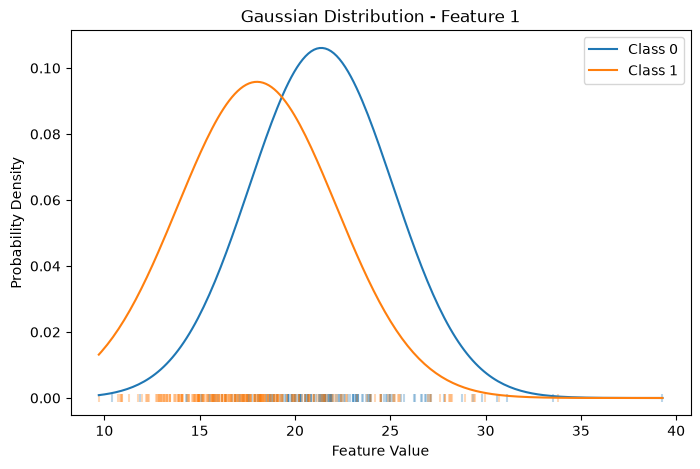

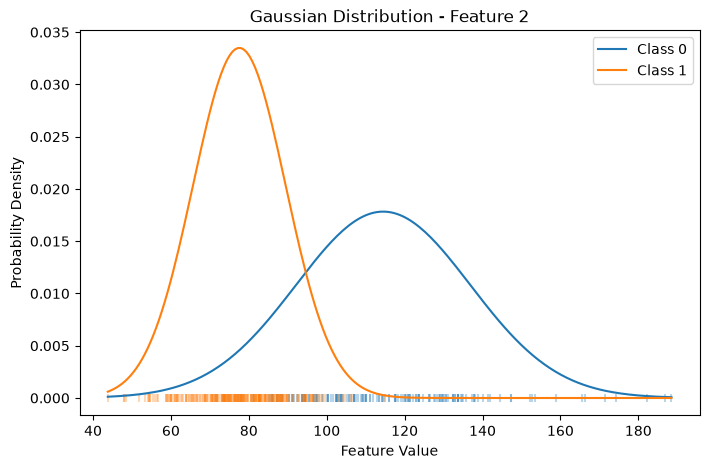

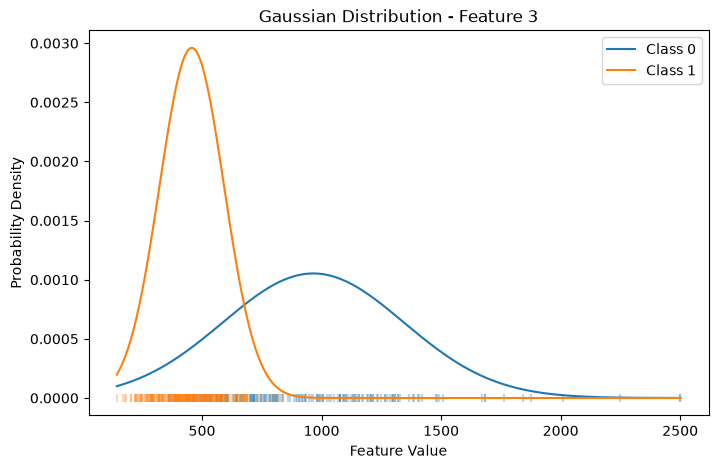

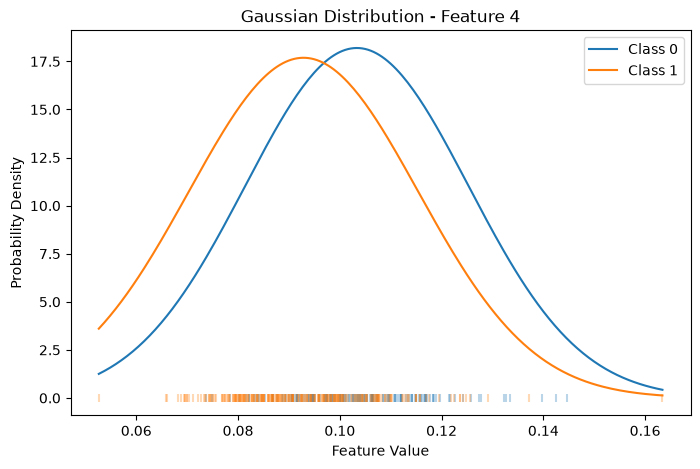

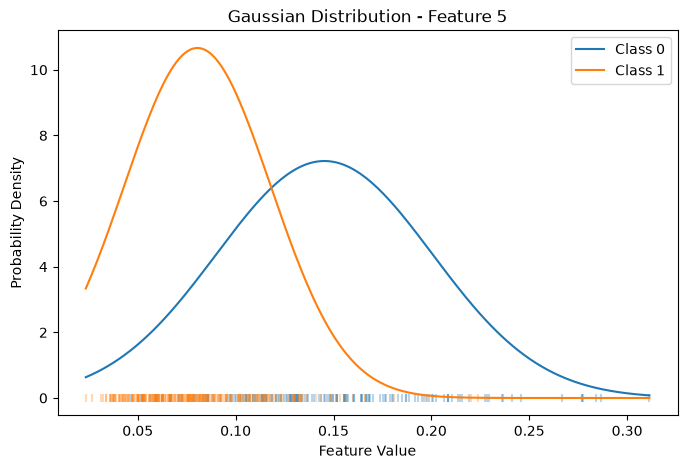

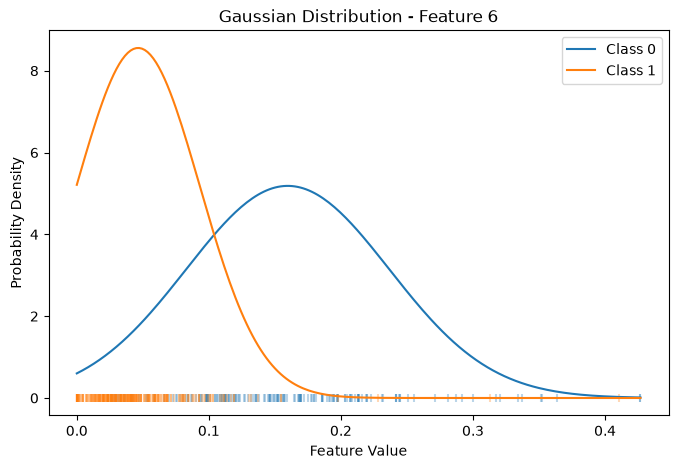

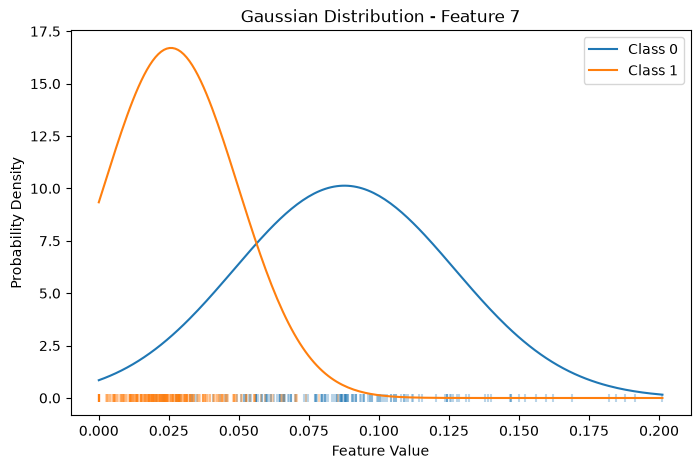

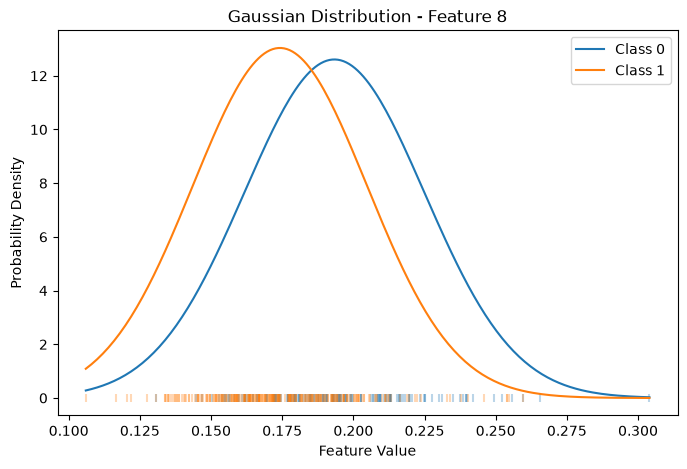

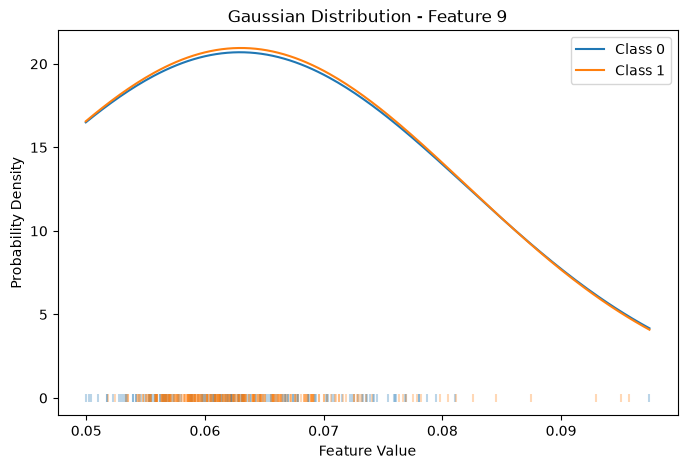

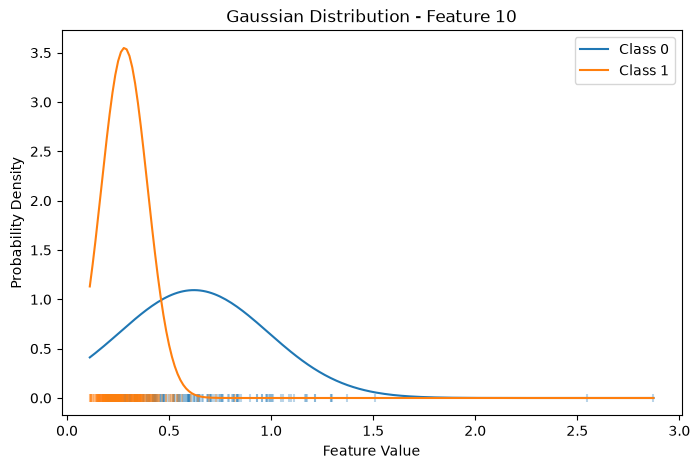

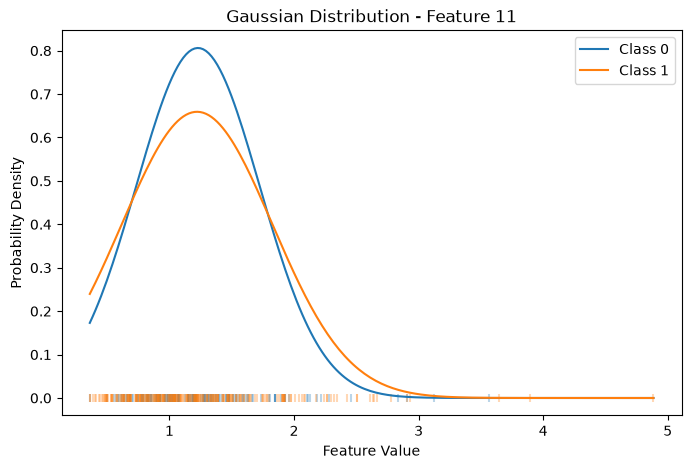

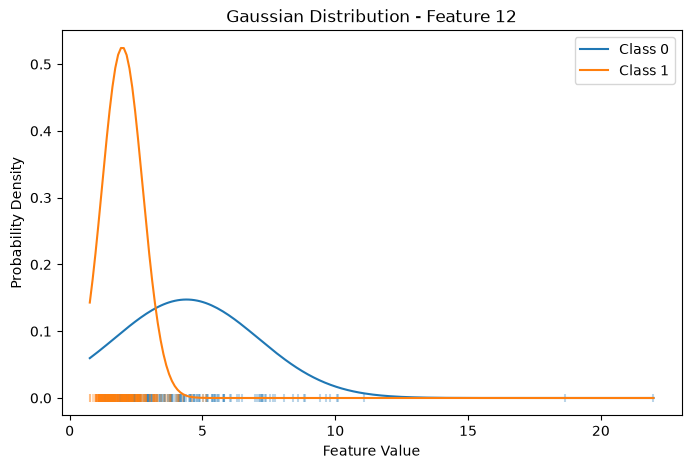

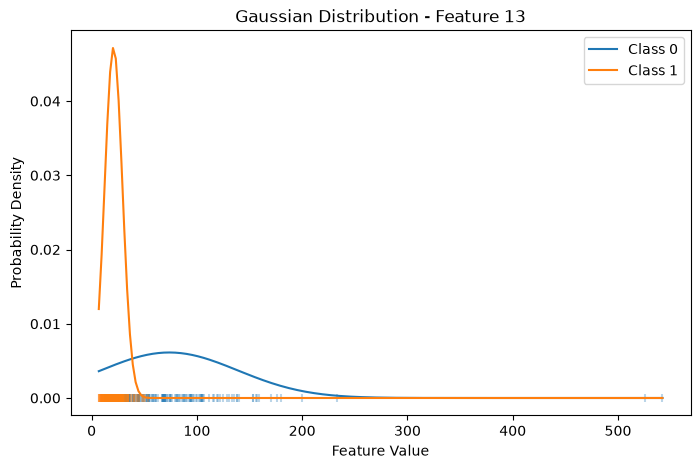

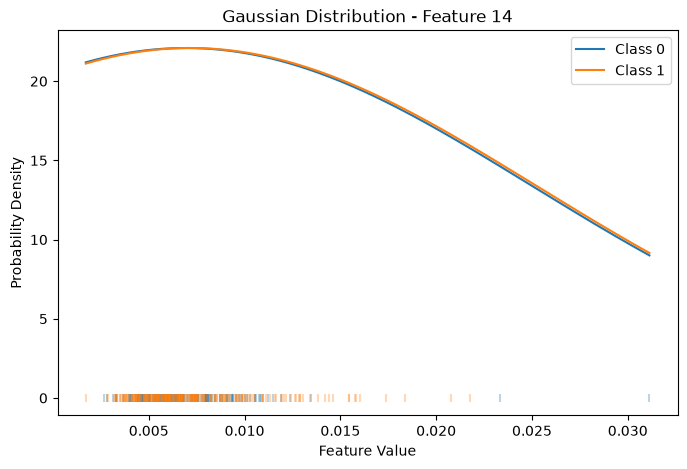

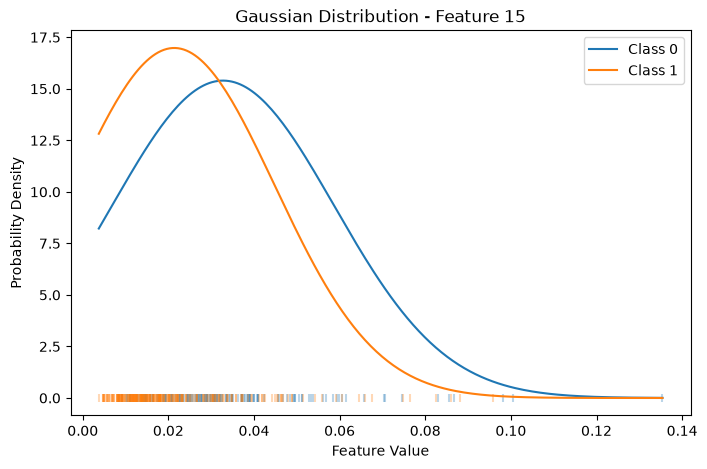

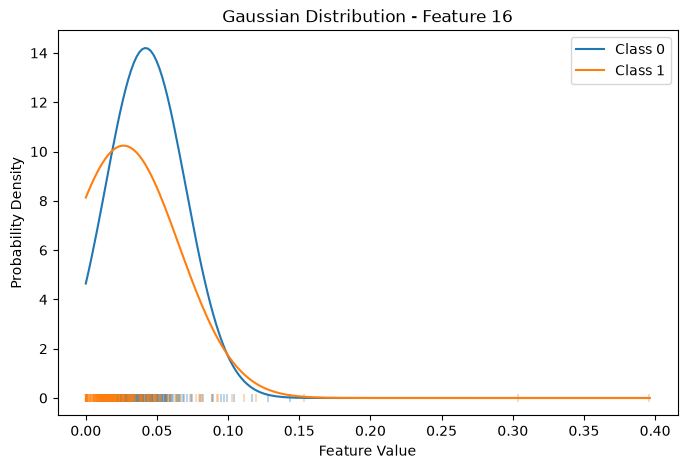

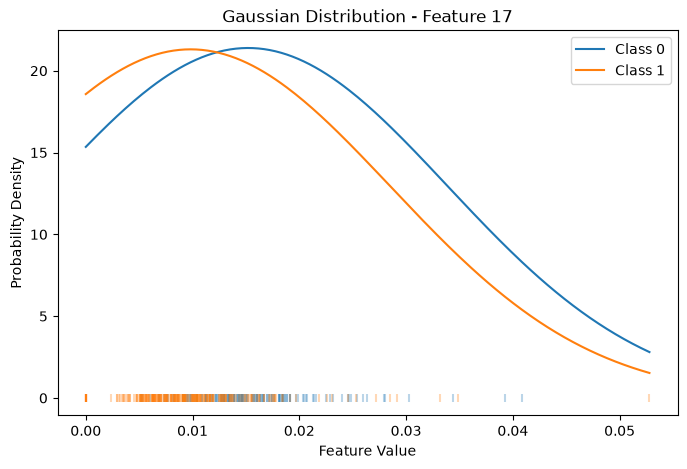

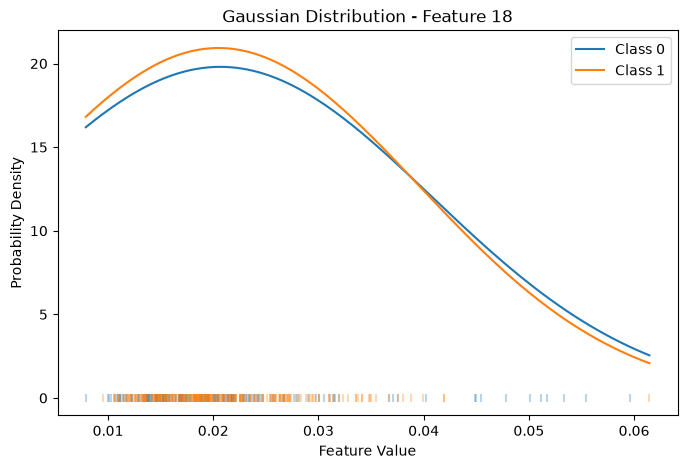

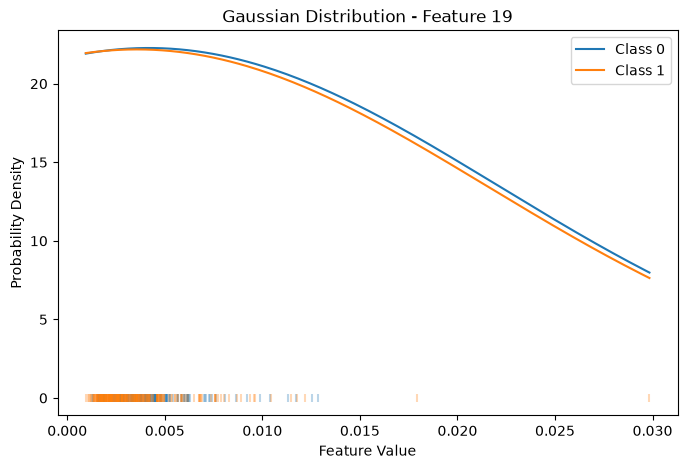

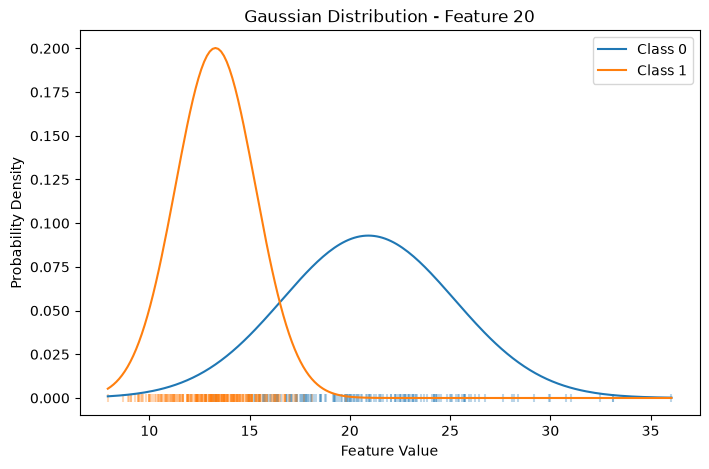

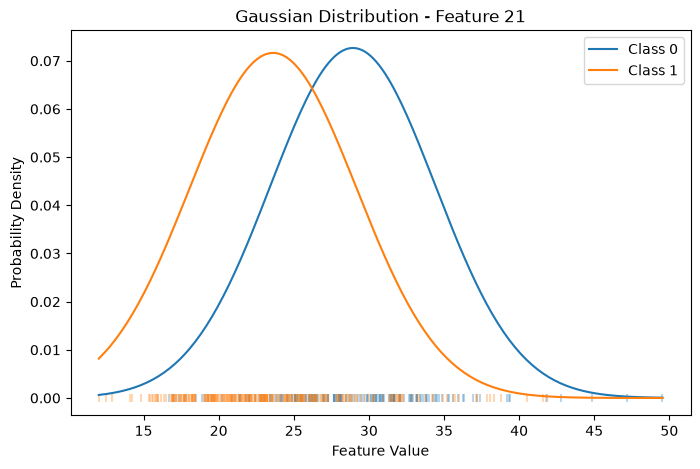

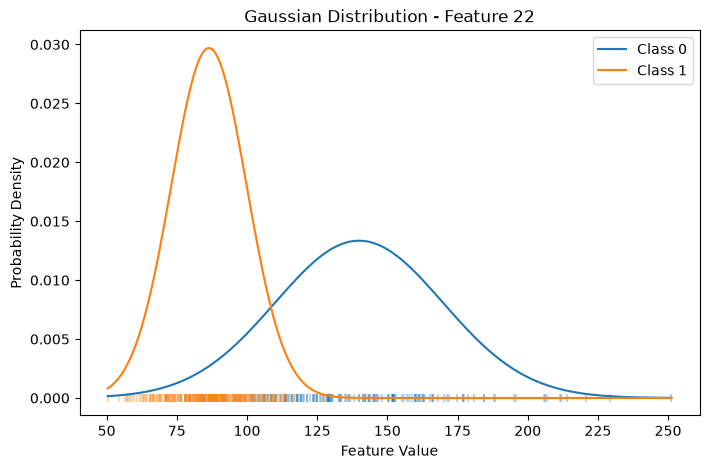

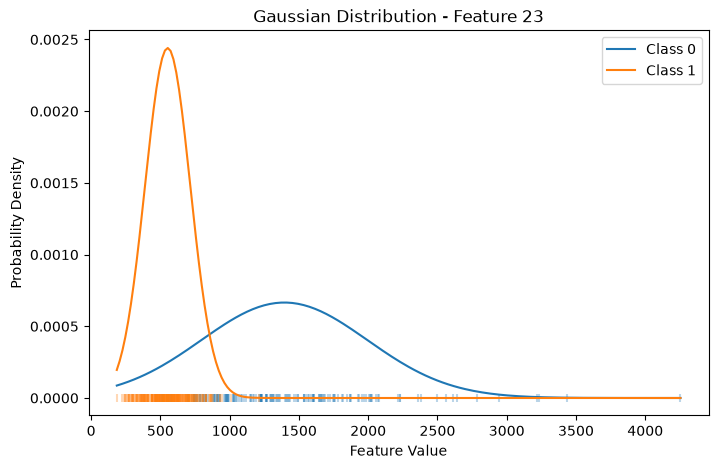

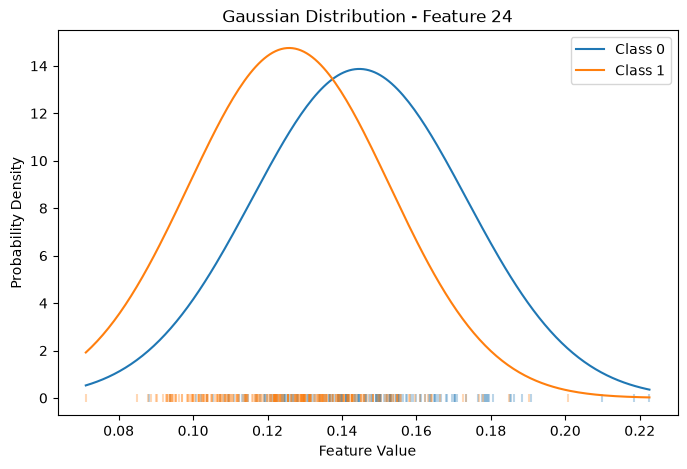

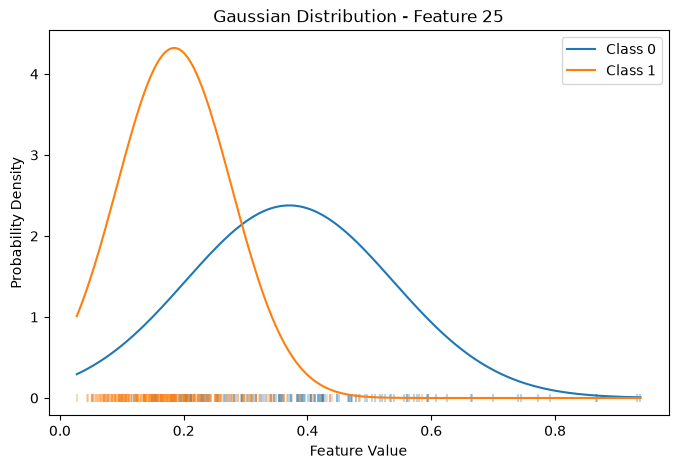

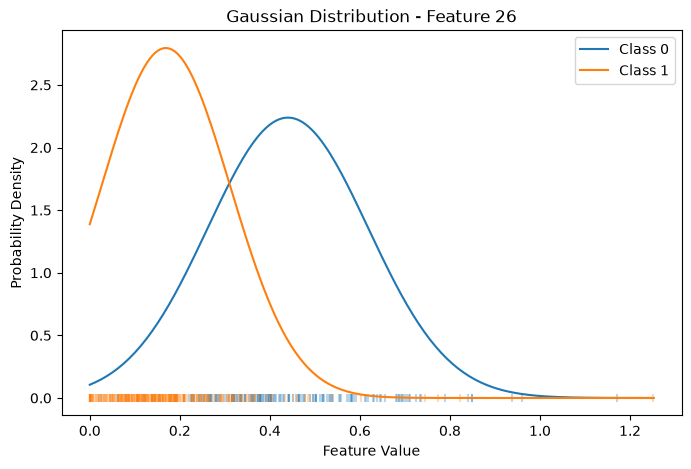

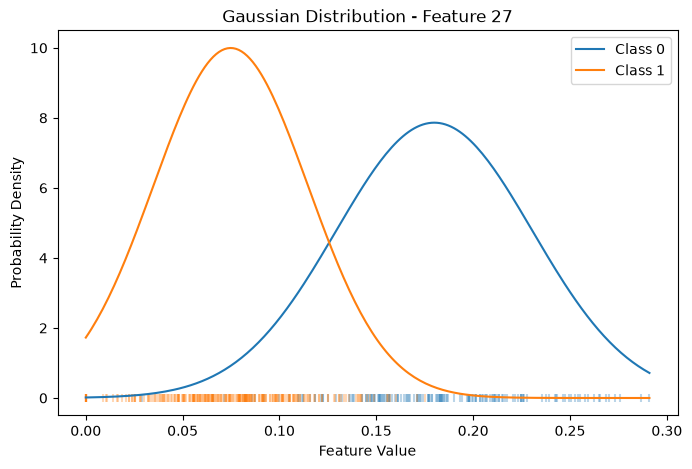

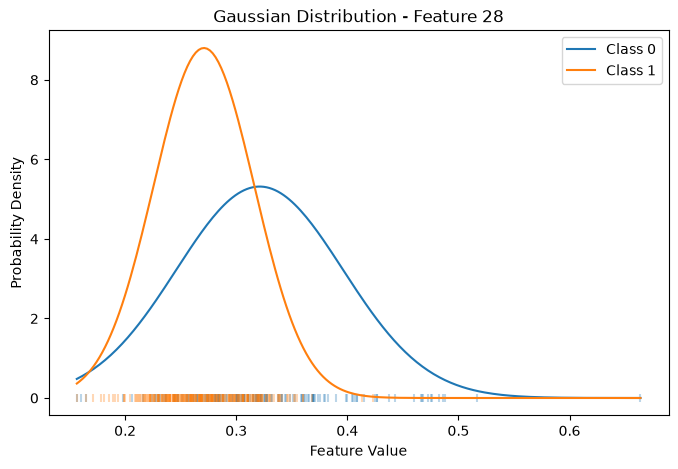

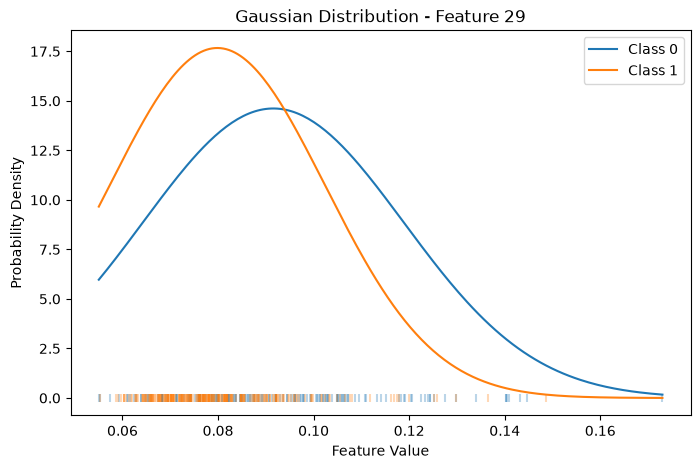

In [273]:
for feature_index in range(X_train.shape[1]):
    plt.figure(figsize=(8,5))
    for class_index, cl in enumerate(gnb_model.classes):
        mean= gnb_model.theta[class_index, feature_index]
        variance= gnb_model.var[class_index, feature_index]
        
        x_values = np.linspace(X_train[:, feature_index].min(), X_train[:, feature_index].max(),200)
        
        gaussian=(1/ np.sqrt(2 * np.pi * variance)) * np.exp(-((x_values - mean) ** 2) / (2 * variance))
        plt.plot(x_values, gaussian, label=f"Class {cl}")
        class_data = X_train[y_train == cl, feature_index]
        plt.scatter(class_data, np.zeros(len(class_data)), alpha=0.3, marker="|")
    plt.title(f"Gaussian Distribution - Feature {feature_index}")
    plt.xlabel("Feature Value")
    plt.ylabel("Probability Density")
    plt.legend()
    plt.show()

---
**5.2-Decision Regions**

In [274]:
X_train_2d= X_train[:,[0,1]]
X_test_2d= X_test[:,[0,1]]

In [275]:
print(X_train_2d.shape)
print(X_test_2d.shape)

(456, 2)
(113, 2)


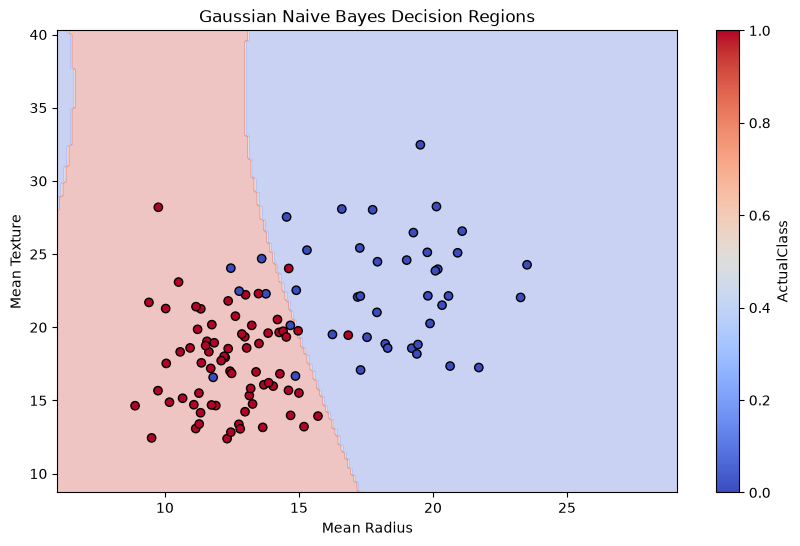

In [276]:
decision_model = GNBayes()
decision_model.fit(X_train_2d, y_train)

x_min = X_train_2d[:, 0].min() - 1
x_max = X_train_2d[:, 0].max() + 1
y_min = X_train_2d[:, 1].min() - 1
y_max = X_train_2d[:, 1].max() + 1

xx,yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                    np.linspace(y_min, y_max, 200))

grid_points = np.c_[xx.ravel(), yy.ravel()]
Z = decision_model.predict(grid_points)
Z = Z.reshape(xx.shape)


plt.figure(figsize=(10,6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")

plt.scatter(X_test_2d[:,0], X_test_2d[:,1], c=y_test, edgecolors="black",cmap="coolwarm")


plt.title("Gaussian Naive Bayes Decision Regions")
plt.xlabel("Mean Radius")
plt.ylabel("Mean Texture")
plt.colorbar(label="ActualClass")
plt.show()

**Why are decision boundaries curved?**

The decision boundary can be curved because Gaussian Naive Bayes calculates a separate variance for each feature in each class. When these variances differ, the squared terms in the Gaussian probability calculations can produce a quadratic decision boundary instead of a straight line.

---
# *Task six : Compare with scikit-learn :*
---

**6.1) Train the Scikit-learn model :**

In [277]:
from sklearn.naive_bayes import GaussianNB

sklearn_model = GaussianNB(var_smoothing=1e-9)

sklearn_model.fit(X_train, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[170.,286.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.37,0.63]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,0.0003166
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,30
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 30)","[[ 17.33, 21.38,114.49,..., 0.18, 0.32, 0.09], [ 12.07, 18.01, 77.56,..., 0.07, 0.27, 0.08]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 30)","[[ 10.69, 14.14,500.54,..., 0. , 0.01, 0. ], [ 3.24, 17.33,141.83,..., 0. , 0. , 0. ]]"


**6.2) compare the learned parameters :**

In [278]:
print("Class priors match:", np.allclose(gnb_model.class_prior, sklearn_model.class_prior_))

print("Means match:", np.allclose(gnb_model.theta, sklearn_model.theta_))

print("Variances match:", np.allclose(gnb_model.var, sklearn_model.var_))

Class priors match: True
Means match: True
Variances match: True


**6.3) Compare predicted probabilities :**

For every test sample,  calculate both models' probability of belonging to each class.

In [279]:
GNBayes_probabilities = gnb_model.predict_proba(X_test)
sklearn_probabilities = sklearn_model.predict_proba(X_test)

print("Probabilities match:", np.allclose(GNBayes_probabilities, sklearn_probabilities))

Probabilities match: True


**6.4) Compare predictions :**

In [280]:
GNBayes_predictions = gnb_model.predict(X_test)
sklearn_predictions = sklearn_model.predict(X_test)

agreement = np.mean(GNBayes_predictions == sklearn_predictions)

print("Predictions match:", np.array_equal(GNBayes_predictions, sklearn_predictions))

print("Prediction agreement:", agreement)

Predictions match: True
Prediction agreement: 1.0


### Comparison with Scikit-learn

We compared our Gaussian Naive Bayes implementation with Scikit-learn's `GaussianNB`, using the same training data and variance smoothing value.

| Comparison | Result |
|---|---|
| Class priors | Match |
| Means | Match |
| Variances | Match |
| Predicted probabilities | Match |
| Predicted classes | Match |
| Prediction agreement | 100% |

All parameter and probability comparisons returned `True` using `np.allclose()`. Both models also produced identical predictions for all test samples.

This confirms that our implementation correctly calculates the Gaussian Naive Bayes parameters, probabilities, and final predictions, and behaves consistently with Scikit-learn's implementation.

---
# *Task Seven: Short Questions*
---


**1.Why is the classifier called "naive"? Give an example where the assumption is clearly false.**

It is called "naive" because it assumes that all features are conditionally independent given the class, so the likelihood can be written as a simple product of per-feature terms. This is a strong simplification, since real features are often correlated. In the Breast Cancer dataset, mean radius, mean perimeter and mean area are almost perfectly related, because the area of a roughly round nucleus is determined by its radius, even within a single class. Our duplication experiment is the extreme case, because a copied column is perfectly correlated with the original but is still treated as new evidence.

---

**2.Why can we ignore P(x) when predicting the class?**

P(x) is the denominator of Bayes' theorem, and it is the same number for every class because it does not depend on c. When we compare classes, a common positive factor cannot change which one has the largest value, so the argmax is the same with or without it. We only need P(x) if we want properly normalized probabilities, which is why predict_proba divides by the sum of the (exponentiated) scores. For predict, skipping it saves computation and avoids an unnecessary step.

---

---